# 22 - Features de precipitação

| | |
|---|---|
| **Tarefa do plano** | S2-05 - acumulados de 3/7/14/30 dias e anomalias (2006–2026) |
| **O que faz** | Transforma a chuva diária em indicadores de risco de cheia |
| **Usa** | CHIRPS e IMERG diários (notebooks 03 e 04) |
| **Produz** | `data/processed/series/rain_daily.csv` e `rain_monthly.csv` |

**Ideia simples.** Uma cheia raramente vem de um só dia de chuva: vem da chuva
acumulada em vários dias, sobre solo já molhado. Por isso calcula-se:

- **Acumulados** de 3, 7, 14 e 30 dias (`p3`, `p7`, `p14`, `p30`).
- **Anomalia em percentil**: compara o acumulado de hoje com o da mesma altura do
  ano em todos os anos. 50 = normal; acima de 90 = raro; perto de 100 = extremo.

Tudo é calculado para duas áreas: a **bacia** inteira (a água que chega pelo rio) e
o **distrito** (a chuva local).

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config" / "config.yaml").exists())
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from ete import config, drivers, features, rasters, series, training
from ete import grid as G

cfg = config.load_config()
P = cfg["processing"]
REPORTS = config.path(cfg, "reports", "semana_2")       # figuras e tabelas para o relatório
pd.set_option("display.float_format", "{:,.3f}".format)

In [2]:
daily, monthly = drivers.build_rain_tables(cfg)
print("diário :", daily.shape, "|", daily.index.min().date(), "a", daily["rain_basin"].last_valid_index().date(), "(CHIRPS)")
print("mensal :", monthly.shape)
daily.loc["2023-02-06":"2023-02-13", ["rain_basin", "p3_basin", "p7_basin", "p30_basin", "p7_pct_basin", "p30_pct_basin"]].round(1)

diário : (7578, 16) | 2006-01-01 a 2026-08-31 (CHIRPS)
mensal : (249, 12)


,rain_basin,p3_basin,p7_basin,p30_basin,p7_pct_basin,p30_pct_basin
date,,,,,,
2023-02-06,0.000,0.000,48.600,69.200,74.700,8.900
2023-02-07,2.500,2.500,47.400,71.700,73.700,10.200
2023-02-08,55.200,57.700,88.200,125.600,92.800,42.600
2023-02-09,63.700,121.400,135.300,189.300,98.500,81.400
2023-02-10,39.700,158.600,161.100,229.000,99.200,88.900
2023-02-11,11.800,115.100,172.900,240.800,99.400,91.000
2023-02-12,43.300,94.700,216.100,284.000,99.700,92.100
2023-02-13,22.500,77.500,238.600,306.500,99.800,93.500


## 1. Os episódios de chuva mais fortes na bacia (acumulado de 7 dias)

In [3]:
p7 = daily["p7_basin"].dropna()
peaks = p7[(p7 == p7.rolling(31, center=True, min_periods=1).max())].nlargest(12)     # picos separados por 15 dias
eventos = pd.DataFrame({"chuva_7_dias_mm": peaks.round(0), "percentil": daily.loc[peaks.index, "p7_pct_basin"].round(1),
                        "chuva_30_dias_mm": daily.loc[peaks.index, "p30_basin"].round(0)})
eventos.index = eventos.index.strftime("%Y-%m-%d"); eventos.index.name = "fim do episódio"
eventos.to_csv(REPORTS / "22_maiores_episodios_de_chuva.csv")
eventos

,chuva_7_dias_mm,percentil,chuva_30_dias_mm
fim do episódio,,,
2023-02-14,244.000,100.000,314.000
2026-01-19,208.000,100.000,394.000
2013-01-21,154.000,99.500,252.000
2021-02-05,152.000,98.900,305.000
2014-03-10,148.000,100.000,197.000
2025-11-30,138.000,100.000,222.000
2024-03-14,123.000,99.500,167.000
2017-02-20,113.000,97.400,239.000
2006-01-09,105.000,98.200,NaN


## 2. Como ler os indicadores num ano

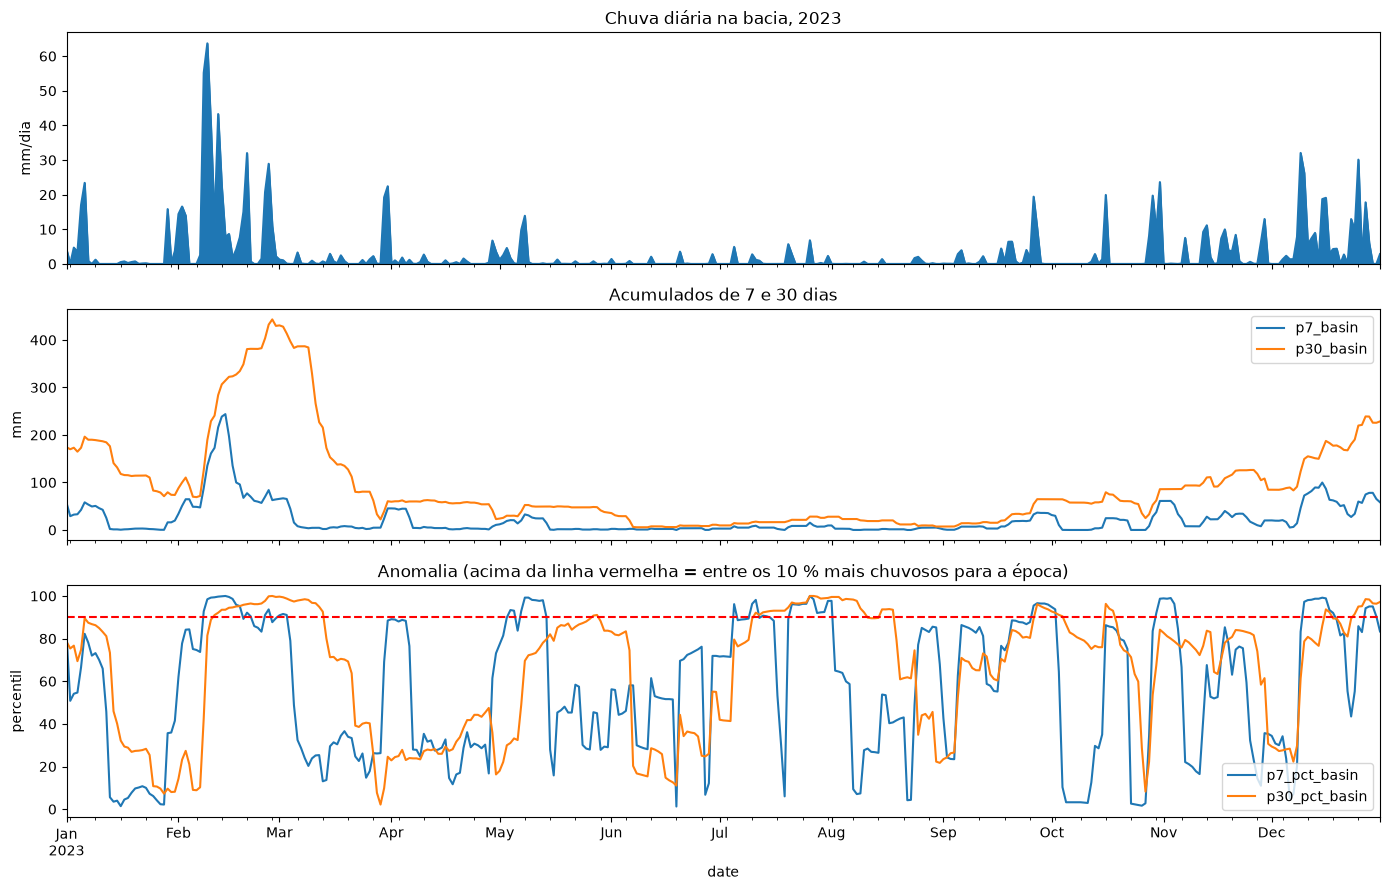

In [4]:
YEAR = "2023"
fig, axes = plt.subplots(3, 1, figsize=(14, 9), sharex=True)
daily.loc[YEAR, "rain_basin"].plot.area(ax=axes[0], color="tab:blue"); axes[0].set_ylabel("mm/dia"); axes[0].set_title(f"Chuva diária na bacia, {YEAR}")
daily.loc[YEAR, ["p7_basin", "p30_basin"]].plot(ax=axes[1]); axes[1].set_ylabel("mm"); axes[1].set_title("Acumulados de 7 e 30 dias")
daily.loc[YEAR, ["p7_pct_basin", "p30_pct_basin"]].plot(ax=axes[2]); axes[2].axhline(90, color="red", linestyle="--")
axes[2].set_ylabel("percentil"); axes[2].set_title("Anomalia (acima da linha vermelha = entre os 10 % mais chuvosos para a época)")
plt.tight_layout(); plt.savefig(REPORTS / "22_chuva_indicadores.png", dpi=110)

## 3. Chuva mensal: anos e meses fora do normal

Cada quadrado é um mês; a cor é o percentil da chuva desse mês face ao mesmo mês
nos outros anos (vermelho escuro = muito acima do normal).

,chuva na bacia (mm)
month,
2023-02,426.000
2026-01,355.000
2021-02,289.000
2021-01,240.000
2023-12,229.000
2026-03,227.000
2025-11,222.000
2013-01,219.000


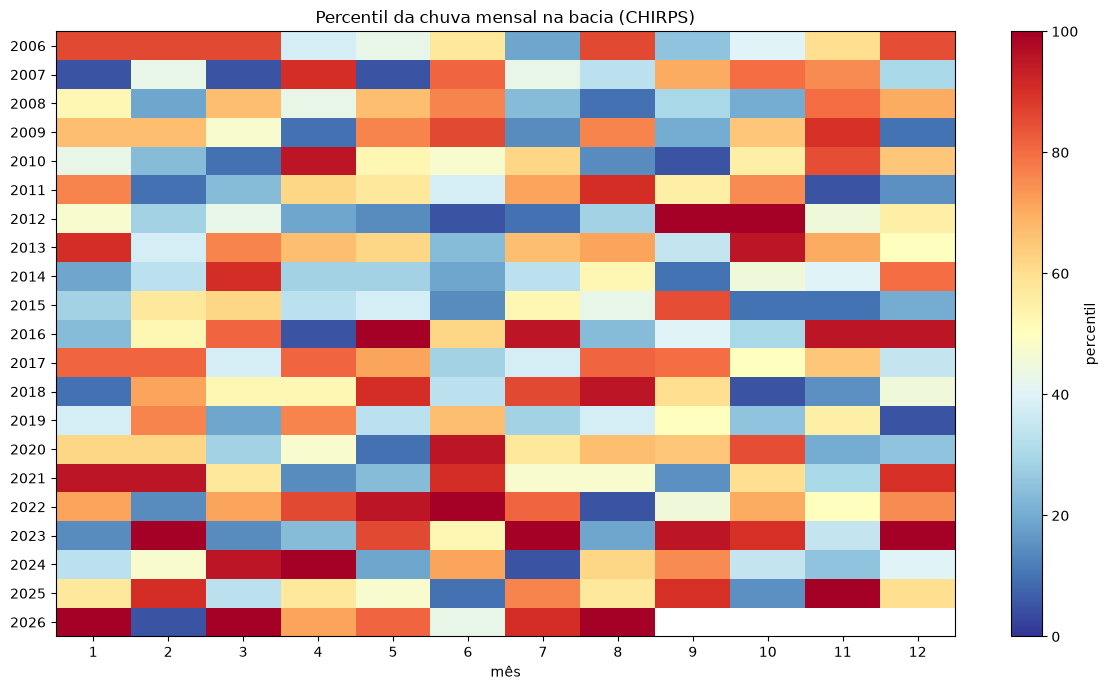

In [5]:
pct = monthly["rain_basin_pct"].copy()
pct.index = pd.MultiIndex.from_tuples([(m[:4], int(m[5:])) for m in pct.index], names=["ano", "mês"])
grid_pct = pct.unstack("mês")
fig, ax = plt.subplots(figsize=(12, 7))
im = ax.imshow(grid_pct.values, cmap="RdYlBu_r", vmin=0, vmax=100, aspect="auto")
ax.set_xticks(range(12), range(1, 13)); ax.set_yticks(range(len(grid_pct)), grid_pct.index)
ax.set_xlabel("mês"); ax.set_title("Percentil da chuva mensal na bacia (CHIRPS)"); plt.colorbar(im, ax=ax, label="percentil")
plt.tight_layout(); plt.savefig(REPORTS / "22_chuva_mensal_percentil.png", dpi=110)
monthly["rain_basin_mm"].nlargest(8).round(0).to_frame("chuva na bacia (mm)")

**Limites a ter em conta**

- O CHIRPS é publicado com cerca de um mês de atraso: o último mês pode estar em
  falta. Para o tempo quase real usa-se o IMERG, guardado ao lado (`imerg_*`).
- O percentil é calculado com os próprios 20 anos, incluindo o ano em causa. Com
  só 20 anos, "percentil 100" significa "o maior destes 20 anos", não um período
  de retorno.